# Credit Card Fraud Detection - Model Selection

This notebook compares three classification models:

- K-Nearest Neighbors (KNN)
- Random Forest
- Support Vector Machine (SVM)

The models will be compared using Accuracy, Precision, Recall, F1 Score, and ROC-AUC.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

## Step 1: Load the Cleaned Dataset

Load the cleaned credit card fraud dataset produced during preprocessing.

In [2]:
df = pd.read_csv("Data/credit_fraud_data.csv")

print(df.shape)
df.head()

(100000, 50)


,transaction_datetime,merchant_category,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,account_age_days,credit_limit,credit_score,...,travel_trans_outlier,lodging_trans_outlier,clothing_trans_outlier,entertainment_trans_outlier,transportation_trans_outlier,home_trans_outlier,education_trans_outlier,utilities_trans_outlier,financial_trans_outlier,age_group
0,2026-01-01 02:28:51,Healthcare & Pharmacy,2,Monday,0,41,Female,709,6630.0,742,...,0,0,0,0,0,0,0,0,0,Adult
1,2026-01-01 03:15:18,Restaurant & Dining,3,Monday,1,56,Male,1143,4350.0,602,...,0,0,0,0,0,0,0,0,0,Adult
2,2026-01-01 03:44:38,Grocery & Supermarket,3,Monday,0,43,Male,601,3950.0,605,...,0,0,0,0,0,0,0,0,0,Adult
3,2026-01-01 03:53:41,Gas Station,3,Monday,0,51,Female,582,13870.0,675,...,0,0,0,0,0,0,0,0,0,Adult
4,2026-01-01 04:29:08,Clothing & Apparel,4,Monday,1,40,Female,711,6570.0,743,...,0,0,0,0,0,0,0,0,0,Adult


## Step 2: Check Dataset Columns

Check the available columns and identify the fraud target column.

In [3]:
df.columns.tolist()

['transaction_datetime',
 'merchant_category',
 'transaction_hour',
 'transaction_day_of_week',
 'card_present',
 'customer_age',
 'customer_gender',
 'account_age_days',
 'credit_limit',
 'credit_score',
 'num_cards_held',
 'transactions_last_1h',
 'transactions_last_24h',
 'transactions_last_7d',
 'amount_last_1h',
 'amount_last_24h',
 'days_since_last_transaction',
 'distance_from_home_km',
 'distance_from_last_tx_km',
 'international_transaction',
 'high_risk_country',
 'amount_vs_avg_ratio',
 'used_chip',
 'used_pin',
 'transaction_channel',
 'device_type',
 'browser',
 'is_weekend',
 'avg_transaction_amount_30d',
 'std_transaction_amount_30d',
 'num_declined_last_30d',
 'num_chargebacks_ever',
 'email_domain',
 'is_fraud',
 'online_retail_trans_outlier',
 'restaurant_trans_outlier',
 'grocery_trans_outlier',
 'gasstation_trans_outlier',
 'healthcare_trans_outlier',
 'tech_trans_outlier',
 'travel_trans_outlier',
 'lodging_trans_outlier',
 'clothing_trans_outlier',
 'entertainment

## Step 3: Separate Features and Target

Separate the target variable from the input features.

`X` contains the features used for prediction and `y` contains the fraud labels.

In [4]:
target_col = "is_fraud"

In [5]:
X = df.drop(columns=[target_col]).copy()
y = df[target_col].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass counts:")
print(y.value_counts())

print("\nClass percentages:")
print(y.value_counts(normalize=True))

X shape: (100000, 49)
y shape: (100000,)

Class counts:
is_fraud
0    97945
1     2055
Name: count, dtype: int64

Class percentages:
is_fraud
0    0.97945
1    0.02055
Name: proportion, dtype: float64


## Step 4: Remove Datetime Columns

Some columns contain dates and times stored as text.

These raw datetime columns are removed because the machine learning models require numeric or encoded features.

In [6]:
datetime_columns = []

for col in X.select_dtypes(include="object").columns:
    converted = pd.to_datetime(X[col], errors="coerce")

    if converted.notna().mean() > 0.8:
        datetime_columns.append(col)

print("Datetime columns removed:", datetime_columns)

X = X.drop(columns=datetime_columns)

Datetime columns removed: ['transaction_datetime']


/tmp/ipykernel_116929/2979526385.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X.select_dtypes(include="object").columns:
/tmp/ipykernel_116929/2979526385.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  converted = pd.to_datetime(X[col], errors="coerce")
/tmp/ipykernel_116929/2979526385.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is

In [7]:
print("Remaining non-numeric columns:")
print(X.select_dtypes(exclude=np.number).columns.tolist())

Remaining non-numeric columns:
['merchant_category', 'transaction_day_of_week', 'customer_gender', 'transaction_channel', 'device_type', 'browser', 'email_domain', 'age_group']


## Step 5: Prepare Numerical and Categorical Features

Numerical features are standardized.

Categorical features are converted into numeric values using One-Hot Encoding so they can be used by the classification models.

In [8]:
numeric_features = X.select_dtypes(include=np.number).columns
categorical_features = X.select_dtypes(exclude=np.number).columns

print("Number of numerical features:", len(numeric_features))
print("Categorical features:", categorical_features.tolist())

Number of numerical features: 40
Categorical features: ['merchant_category', 'transaction_day_of_week', 'customer_gender', 'transaction_channel', 'device_type', 'browser', 'email_domain', 'age_group']


In [9]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

## Step 6: Split the Dataset

Split the data into training and testing sets.

Stratification keeps approximately the same fraud and non-fraud proportions in both datasets.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (80000, 48)
Testing set: (20000, 48)


## Step 7: Create the Classification Models

Create the three target models:

1. K-Nearest Neighbors
2. Random Forest
3. Support Vector Machine

The preprocessing step is included in each model pipeline.

In [11]:
from sklearn.svm import LinearSVC

models = {
    "KNN": make_pipeline(
        preprocessor,
        KNeighborsClassifier(
            n_neighbors=5,
            n_jobs=-1
        )
    ),

    "Random Forest": make_pipeline(
        preprocessor,
        RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced",
            random_state=42,
            n_jobs=1
        )
    ),

    "SVM": make_pipeline(
        preprocessor,
        LinearSVC(
            class_weight="balanced",
            random_state=42,
            max_iter=5000,
            dual="auto"
        )
    )
}

## Step 8: Set Up Cross-Validation

Use 5-fold Stratified Cross-Validation to evaluate each model.

The models are compared using:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC

In [12]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

## Step 9: Compare the Models

Evaluate KNN, Random Forest, and SVM using cross-validation.

The average scores are stored in a table for comparison.

In [13]:
results = []

for name, model in models.items():

    print("Running:", name)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

    print("Finished:", name)

results_df = pd.DataFrame(results)

results_df

Running: KNN
Finished: KNN
Running: Random Forest
Finished: Random Forest
Running: SVM
Finished: SVM


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,KNN,0.978987,0.211353,0.008516,0.016364,0.594732
1,Random Forest,0.979350,0.394896,0.009732,0.018956,0.810123
2,SVM,0.718425,0.055290,0.789538,0.103339,0.829783


## Step 10: Visualize Model Performance

Create a bar chart to compare the evaluation scores of the three models.

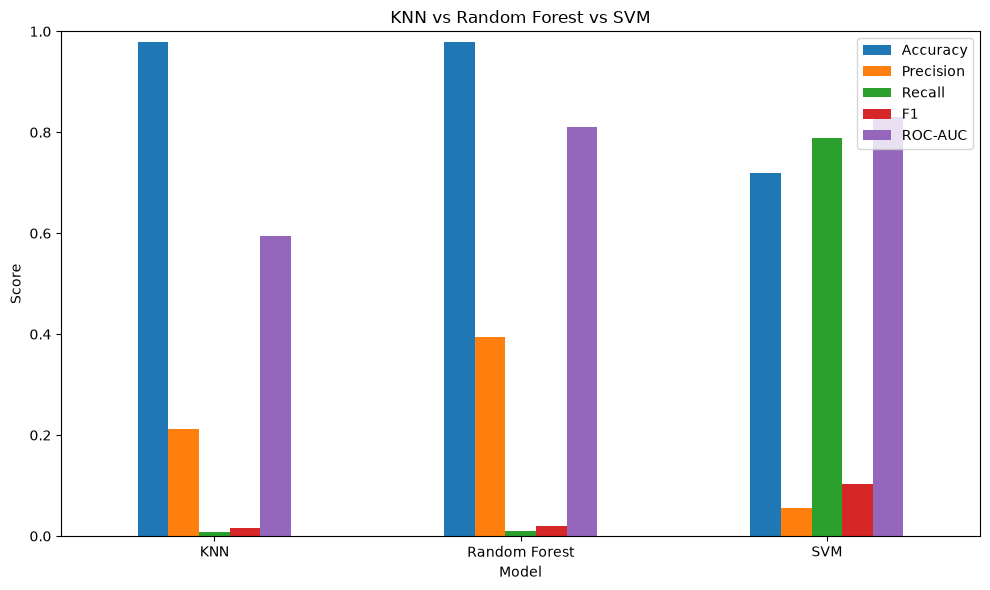

In [14]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("KNN vs Random Forest vs SVM")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

## Step 11: Select the Best Model

Select the model with the highest F1 Score.

F1 Score considers both Precision and Recall, making it useful for fraud detection.

In [15]:
results_df = results_df.sort_values(
    by="F1",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
2,SVM,0.718425,0.055290,0.789538,0.103339,0.829783
1,Random Forest,0.979350,0.394896,0.009732,0.018956,0.810123
0,KNN,0.978987,0.211353,0.008516,0.016364,0.594732


In [16]:
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("Best model:", best_model_name)

Best model: SVM


## Step 12: Train the Best Model

Train the selected model using the complete training dataset and make predictions on the test dataset.

In [17]:
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

## Step 13: Final Model Evaluation

Evaluate the selected model using Accuracy, Precision, Recall, F1 Score, and a Classification Report.

Recall is especially important because it measures how many actual fraud cases were detected.

In [18]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.716
Precision: 0.0550582671845972
Recall: 0.7931873479318735
F1 Score: 0.10296904611497157

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.71      0.83     19589
           1       0.06      0.79      0.10       411

    accuracy                           0.72     20000
   macro avg       0.52      0.75      0.47     20000
weighted avg       0.97      0.72      0.82     20000



## Step 14: ROC-AUC

Calculate the ROC-AUC score of the final model.

ROC-AUC measures how well the model distinguishes fraud from non-fraud transactions.

In [19]:
if hasattr(best_model, "predict_proba"):

    y_prob = best_model.predict_proba(X_test)[:, 1]

    print(
        "ROC-AUC:",
        roc_auc_score(y_test, y_prob)
    )

## Step 15: Confusion Matrix

Display the confusion matrix for the selected model.

False negatives are especially important because they represent fraudulent transactions that the model failed to detect.

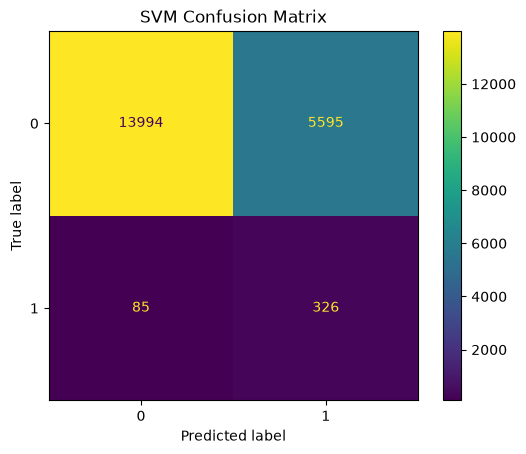

In [20]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title(best_model_name + " Confusion Matrix")

plt.show()

## Conclusion

KNN, Random Forest, and SVM were compared using Accuracy, Precision, Recall, F1 Score, and ROC-AUC.

The best model was selected using F1 Score because fraud detection requires a balance between detecting fraudulent transactions and avoiding incorrect fraud predictions.

Recall is also important because it shows how many actual fraudulent transactions were successfully detected.